## **1. IMPORT LIBRARIES**

In [29]:
import sys
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

sys.path.append(os.path.abspath(".."))

from src.ETL import PROCESSED_DIR, MODELS_DIR

os.makedirs(MODELS_DIR, exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


## **2. LOAD DATASET**

In [30]:
df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "historical_clean_bhopal.csv")
)

features = [
    'temperature_2m',
    'relative_humidity_2m',
    'precipitation',
    'wind_speed_10m',
    'hour',
    'month'
]

target_col = 'temperature_2m'

# Check required columns
required_columns = features

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Check missing values
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df[features].isnull().sum())

# Keep only required columns for this model
df = df[features].copy()

# Ensure numerical data
df = df.apply(pd.to_numeric, errors='coerce')

# Remove rows with missing values
df = df.dropna().reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)


Dataset shape: (17520, 7)

Missing values:
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
hour                    0
month                   0
dtype: int64

Cleaned dataset shape: (17520, 6)


## **3. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT**

In [31]:

# Split the original dataset BEFORE creating sequences

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

print("\nChronological split completed!")


Training rows: 12264
Validation rows: 2628
Testing rows: 2628

Chronological split completed!


## **4. SCALE DATA**

In [32]:
scaler = MinMaxScaler()

# Fit ONLY on training data
scaler.fit(train_df[features])

# Transform all three datasets using the same scaler
train_scaled = scaler.transform(train_df[features])
val_scaled = scaler.transform(val_df[features])
test_scaled = scaler.transform(test_df[features])

# Combine scaled data in original chronological order
scaled_data = np.concatenate(
    [train_scaled, val_scaled, test_scaled],
    axis=0
)

# Save scaler
scaler_path = os.path.join(MODELS_DIR, "scaler_bhopal.pkl")

joblib.dump(scaler, scaler_path)

print("Scaler fitted on training data only!")
print("Scaler saved:", scaler_path)

Scaler fitted on training data only!
Scaler saved: c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\scaler_bhopal.pkl


## **5. CREATE MULTI-STEP SEQUENCES**

In [33]:
seq_length = 48
forecast_horizon = 120

target_idx = features.index(target_col)

def create_sequences(data, start_idx, end_idx, stride=1):

    X, y = [], []

    for i in range(start_idx, end_idx - forecast_horizon + 1, stride):

        # Previous 48 hours
        X.append(
            data[i - seq_length:i]
        )

        # Next 120 hours of temperature
        y.append(
            data[i:i + forecast_horizon, target_idx]
        )

    return np.array(X), np.array(y)


# Training sequences
X_train, y_train = create_sequences(
    scaled_data,
    seq_length,
    train_end
)

# Validation sequences
X_val, y_val = create_sequences(
    scaled_data,
    train_end,
    val_end
)

# Testing sequences
X_test, y_test = create_sequences(
    scaled_data,
    val_end,
    n
)

print("Training shapes:", X_train.shape, y_train.shape)
print("Validation shapes:", X_val.shape, y_val.shape)
print("Testing shapes:", X_test.shape, y_test.shape)

Training shapes: (12097, 48, 6) (12097, 120)
Validation shapes: (2509, 48, 6) (2509, 120)
Testing shapes: (2509, 48, 6) (2509, 120)


## **6. BUILD LSTM MODEL**

In [34]:
model = Sequential([
    Input(shape=(seq_length, len(features))),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32, return_sequences=False),
    Dropout(0.2),

    Dense(64, activation='relu'),

    Dense(forecast_horizon)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 48, 64)         │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 120)            │         7,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,504 (158.22 KB)

 Trainable params: 40,504 (158.22 KB)

 Non-trainable params: 0 (0.00 B)

## **7. CONFIGURE CALLBACKS**

In [35]:
model_path = os.path.join(
    MODELS_DIR,
    "weather_lstm_bhopal_multistep.keras"
)

callbacks = [

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=model_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("Training callbacks configured!")

Training callbacks configured!


## **8. TRAIN MODEL**

In [36]:
print("Training Multi-Step LSTM Model...")

history = model.fit(
    X_train,
    y_train,

    epochs=50,
    batch_size=32,

    validation_data=(X_val, y_val),

    callbacks=callbacks,

    shuffle=True,
    verbose=1
)

print("Training completed!")

Training Multi-Step LSTM Model...
Epoch 1/50
379/379 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.0254 - mae: 0.1115
Epoch 1: val_loss improved from None to 0.00257, saving model to c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\weather_lstm_bhopal_multistep.keras

Epoch 1: finished saving model to c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\weather_lstm_bhopal_multistep.keras
379/379 ━━━━━━━━━━━━━━━━━━━━ 30s 62ms/step - loss: 0.0254 - mae: 0.1115 - val_loss: 0.0026 - val_mae: 0.0406 - learning_rate: 0.0010
Epoch 2/50
378/379 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0051 - mae: 0.0557
Epoch 2: val_loss improved from 0.00257 to 0.00174, saving model to c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\weather_lstm_bhopal_multistep.keras

Epoch 2: finished saving model to c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\weather_lstm_bhopal_multistep.keras
379/379 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - loss: 0.0051 - mae: 0.0557 - val_loss: 0.0017 - val_m

## **9. PLOT TRAINING AND VALIDATION LOSS**

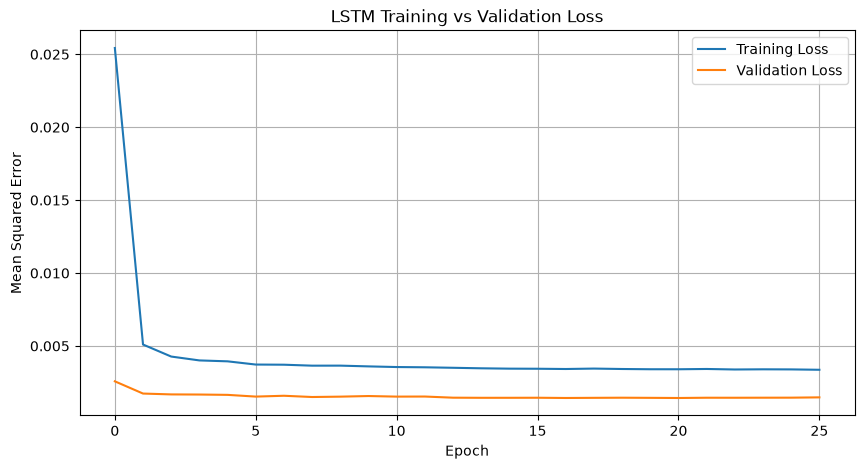

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)
plt.show()

## **10. LOAD MODEL**

In [38]:
from tensorflow.keras.models import load_model

model = load_model(model_path)

print("Best LSTM model loaded successfully!")


Best LSTM model loaded successfully!


## **11. GENERATE TEST PREDICTIONS**

In [39]:
y_pred_scaled = model.predict(X_test)

print("Actual test shape:", y_test.shape)
print("Predicted shape:", y_pred_scaled.shape)

79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step
Actual test shape: (2509, 120)
Predicted shape: (2509, 120)


## **12. CONVERT SCALED VALUES BACK TO CELSIUS**

In [40]:
def inverse_temperature(values):

    values = np.asarray(values)

    dummy = np.zeros(
        (values.size, len(features))
    )

    dummy[:, target_idx] = values.reshape(-1)

    original = scaler.inverse_transform(dummy)

    return original[:, target_idx].reshape(values.shape)


y_test_actual = inverse_temperature(y_test)
y_pred_actual = inverse_temperature(y_pred_scaled)

print("Actual temperatures:", y_test_actual.shape)
print("Predicted temperatures:", y_pred_actual.shape)

print("\nFirst forecast - Actual:")
print(y_test_actual[0])

print("\nFirst forecast - Predicted:")
print(y_pred_actual[0])

Actual temperatures: (2509, 120)
Predicted temperatures: (2509, 120)

First forecast - Actual:
[27.8 28.7 29.  28.5 27.3 26.  25.4 25.1 24.8 24.6 24.4 24.2 23.8 23.8
 23.7 23.6 23.4 23.6 23.3 24.  23.5 23.6 25.  27.1 27.6 28.  28.3 28.5
 28.6 27.2 26.2 25.5 25.2 24.9 24.2 24.  23.8 23.5 23.4 23.3 23.5 23.6
 23.5 23.5 24.1 24.3 24.9 24.7 25.4 27.3 28.2 25.9 25.1 24.4 24.5 24.4
 24.2 24.  23.7 23.6 23.6 23.3 22.8 23.3 23.5 23.6 23.7 23.7 24.  24.5
 23.9 24.6 25.3 25.7 24.6 25.3 24.4 22.8 22.5 22.4 22.4 22.4 22.1 22.2
 22.2 22.  21.9 22.1 22.2 22.5 22.5 22.9 23.2 24.  25.9 26.8 26.1 25.2
 25.7 26.4 26.8 25.4 24.1 23.4 23.1 22.8 22.6 22.6 22.5 22.4 22.3 22.4
 22.2 22.5 22.5 23.8 25.2 26.6 27.6 28.4]

First forecast - Predicted:
[28.54638347 28.59990472 28.39752087 28.16866362 27.51388276 26.83054307
 26.19012767 25.72792941 25.26776516 25.06704541 24.5525586  23.9521964
 23.57618982 23.42514122 23.0643584  23.01179157 23.05730754 23.44772989
 23.9709864  24.81909195 25.83481321 26.69160241

## **13. EVALUATE LSTM MODEL**

In [41]:
actual_flat = y_test_actual.flatten()
predicted_flat = y_pred_actual.flatten()

mae = mean_absolute_error(
    actual_flat,
    predicted_flat
)

rmse = np.sqrt(
    mean_squared_error(actual_flat, predicted_flat)
)

r2 = r2_score(
    actual_flat,
    predicted_flat
)

print("\n===== LSTM MODEL EVALUATION =====")

print(f"MAE  : {mae:.3f} °C")
print(f"RMSE : {rmse:.3f} °C")
print(f"R²   : {r2:.4f}")


===== LSTM MODEL EVALUATION =====
MAE  : 1.208 °C
RMSE : 1.521 °C
R²   : 0.9137


## **14. DAY-WISE LSTM EVALUATION**

In [42]:
day_results = []

for day in range(5):

    start = day * 24
    end = start + 24

    actual_day = y_test_actual[:, start:end].flatten()

    predicted_day = y_pred_actual[:, start:end].flatten()

    day_results.append({

        "Forecast Day": f"Day {day + 1}",

        "MAE (°C)": round(
            mean_absolute_error(actual_day, predicted_day), 3
        ),

        "RMSE (°C)": round(
            np.sqrt(mean_squared_error(actual_day, predicted_day)), 3
        ),

        "R²": round(
            r2_score(actual_day, predicted_day), 4
        )
    })

day_results_df = pd.DataFrame(day_results)

print("\n===== DAY-WISE LSTM EVALUATION =====")
display(day_results_df)


===== DAY-WISE LSTM EVALUATION =====


,Forecast Day,MAE (°C),RMSE (°C),R²
0,Day 1,1.018,1.310,0.9344
1,Day 2,1.134,1.436,0.9221
2,Day 3,1.228,1.544,0.9111
3,Day 4,1.297,1.613,0.9043
4,Day 5,1.363,1.675,0.8976


# **15. PERSISTENCE BASELINE MODEL**

In [43]:
last_temp_scaled = X_test[:, -1, target_idx]

y_persistence_scaled = np.repeat(
    last_temp_scaled.reshape(-1, 1),
    forecast_horizon,
    axis=1
)

y_persistence_actual = inverse_temperature(
    y_persistence_scaled
)

persistence_flat = y_persistence_actual.flatten()

persistence_mae = mean_absolute_error(
    actual_flat,
    persistence_flat
)

persistence_rmse = np.sqrt(
    mean_squared_error(actual_flat, persistence_flat)
)

persistence_r2 = r2_score(
    actual_flat,
    persistence_flat
)

print("\n===== PERSISTENCE MODEL EVALUATION =====")

print(f"MAE  : {persistence_mae:.3f} °C")
print(f"RMSE : {persistence_rmse:.3f} °C")
print(f"R²   : {persistence_r2:.4f}")


===== PERSISTENCE MODEL EVALUATION =====
MAE  : 4.399 °C
RMSE : 5.527 °C
R²   : -0.1395


## **16. SEASONAL NAIVE BASELINE MODEL**

In [44]:
y_seasonal_scaled = np.tile(
    X_test[:, 24:48, target_idx],
    (1, 5)
)

y_seasonal_actual = inverse_temperature(
    y_seasonal_scaled
)

seasonal_flat = y_seasonal_actual.flatten()

seasonal_mae = mean_absolute_error(
    actual_flat,
    seasonal_flat
)

seasonal_rmse = np.sqrt(
    mean_squared_error(actual_flat, seasonal_flat)
)

seasonal_r2 = r2_score(
    actual_flat,
    seasonal_flat
)

print("\n===== SEASONAL NAIVE EVALUATION =====")

print(f"MAE  : {seasonal_mae:.3f} °C")
print(f"RMSE : {seasonal_rmse:.3f} °C")
print(f"R²   : {seasonal_r2:.4f}")


===== SEASONAL NAIVE EVALUATION =====
MAE  : 1.293 °C
RMSE : 1.719 °C
R²   : 0.8898


## **17. FINAL MODEL COMPARISON**

In [45]:

final_comparison = pd.DataFrame({

    "Model": [
        "LSTM",
        "Persistence",
        "Seasonal Naive"
    ],

    "MAE (°C)": [
        mae,
        persistence_mae,
        seasonal_mae
    ],

    "RMSE (°C)": [
        rmse,
        persistence_rmse,
        seasonal_rmse
    ],

    "R²": [
        r2,
        persistence_r2,
        seasonal_r2
    ]
})

print("\n===== FINAL MODEL COMPARISON =====")
display(final_comparison)


===== FINAL MODEL COMPARISON =====


,Model,MAE (°C),RMSE (°C),R²
0,LSTM,1.207912,1.521068,0.913706
1,Persistence,4.398839,5.527197,-0.139451
2,Seasonal Naive,1.292861,1.719119,0.889771


## **18. DAY-WISE BASELINE COMPARISON**

In [46]:
baseline_results = []

for day in range(5):

    start = day * 24
    end = start + 24

    actual_day = y_test_actual[:, start:end].flatten()

    lstm_day = y_pred_actual[:, start:end].flatten()

    seasonal_day = y_seasonal_actual[:, start:end].flatten()

    baseline_results.append({

        "Forecast Day": f"Day {day + 1}",

        "LSTM MAE": round(
            mean_absolute_error(actual_day, lstm_day), 3
        ),

        "Seasonal MAE": round(
            mean_absolute_error(actual_day, seasonal_day), 3
        ),

        "LSTM RMSE": round(
            np.sqrt(mean_squared_error(actual_day, lstm_day)), 3
        ),

        "Seasonal RMSE": round(
            np.sqrt(mean_squared_error(actual_day, seasonal_day)), 3
        )
    })

baseline_comparison = pd.DataFrame(baseline_results)

print("\n===== DAY-WISE BASELINE COMPARISON =====")
display(baseline_comparison)


===== DAY-WISE BASELINE COMPARISON =====


,Forecast Day,LSTM MAE,Seasonal MAE,LSTM RMSE,Seasonal RMSE
0,Day 1,1.018,0.953,1.310,1.319
1,Day 2,1.134,1.197,1.436,1.591
2,Day 3,1.228,1.341,1.544,1.780
3,Day 4,1.297,1.429,1.613,1.863
4,Day 5,1.363,1.544,1.675,1.966


## **19. CALCULATE LSTM IMPROVEMENT**

In [47]:
mae_improvement = (
    (seasonal_mae - mae) / seasonal_mae
) * 100

rmse_improvement = (
    (seasonal_rmse - rmse) / seasonal_rmse
) * 100

print("\n===== LSTM IMPROVEMENT OVER SEASONAL NAIVE =====")

print(f"MAE Improvement : {mae_improvement:.2f}%")
print(f"RMSE Improvement: {rmse_improvement:.2f}%")


===== LSTM IMPROVEMENT OVER SEASONAL NAIVE =====
MAE Improvement : 6.57%
RMSE Improvement: 11.52%


## **20. VISUALIZE ACTUAL VS PREDICTED TEMPERATURE**

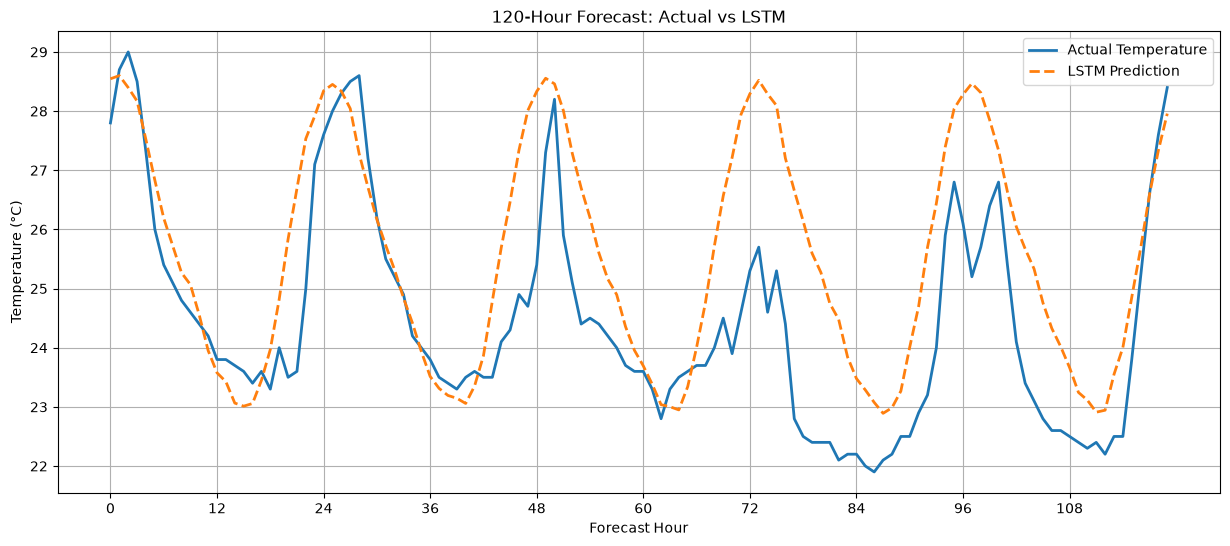

In [48]:
sample_index = 0

plt.figure(figsize=(15, 6))

plt.plot(
    range(120),
    y_test_actual[sample_index],
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    range(120),
    y_pred_actual[sample_index],
    label="LSTM Prediction",
    linestyle='--',
    linewidth=2
)

plt.title("120-Hour Forecast: Actual vs LSTM")

plt.xlabel("Forecast Hour")
plt.ylabel("Temperature (°C)")

plt.xticks(range(0, 120, 12))

plt.legend()
plt.grid(True)
plt.show()

## **21. VISUALIZE ALL THREE MODELS**

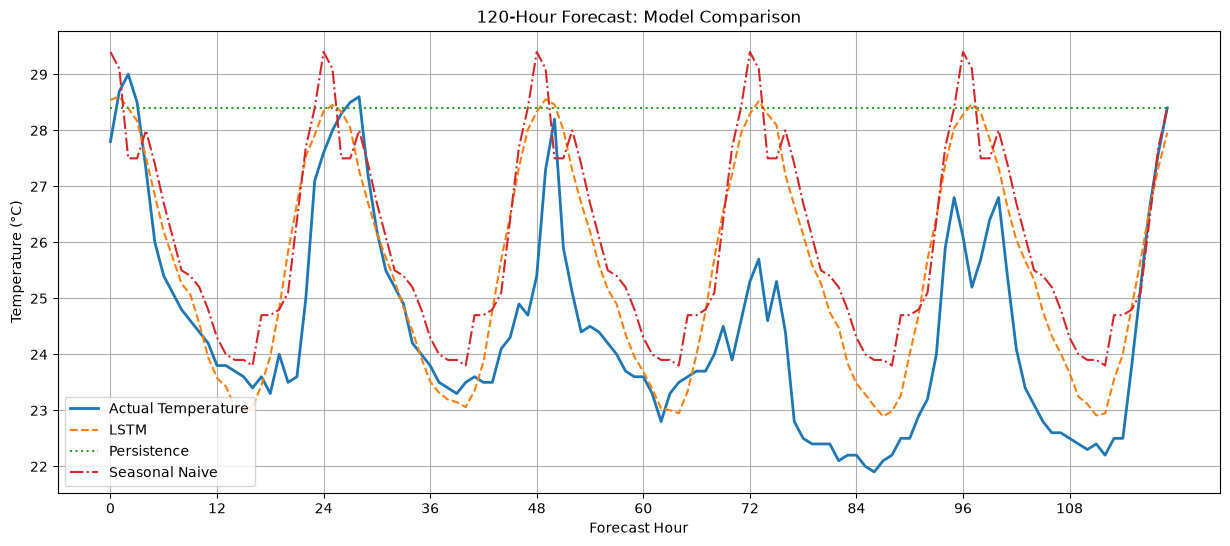

In [49]:
plt.figure(figsize=(15, 6))

plt.plot(
    range(120),
    y_test_actual[sample_index],
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    range(120),
    y_pred_actual[sample_index],
    label="LSTM",
    linestyle='--'
)

plt.plot(
    range(120),
    y_persistence_actual[sample_index],
    label="Persistence",
    linestyle=':'
)

plt.plot(
    range(120),
    y_seasonal_actual[sample_index],
    label="Seasonal Naive",
    linestyle='-.'
)

plt.title("120-Hour Forecast: Model Comparison")

plt.xlabel("Forecast Hour")
plt.ylabel("Temperature (°C)")

plt.xticks(range(0, 120, 12))

plt.legend()
plt.grid(True)
plt.show()

## **22. SAVE EVALUATION RESULT**

In [50]:
evaluation_path = os.path.join(
    PROCESSED_DIR,
    "lstm_evaluation_results.csv"
)

day_results_df.to_csv(
    evaluation_path,
    index=False
)

comparison_path = os.path.join(
    PROCESSED_DIR,
    "lstm_baseline_comparison.csv"
)

final_comparison.to_csv(
    comparison_path,
    index=False
)

print("\n===== SAVED FILES =====")
print("LSTM Model:", model_path)
print("Scaler:", scaler_path)
print("Day-wise Evaluation:", evaluation_path)
print("Model Comparison:", comparison_path)

print("\n===== ALL OPERATIONS COMPLETED SUCCESSFULLY! =====")



===== SAVED FILES =====
LSTM Model: c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\weather_lstm_bhopal_multistep.keras
Scaler: c:\Users\HP\Desktop\PROJECTS\weather-elt-project\models\scaler_bhopal.pkl
Day-wise Evaluation: c:\Users\HP\Desktop\PROJECTS\weather-elt-project\data\processed\lstm_evaluation_results.csv
Model Comparison: c:\Users\HP\Desktop\PROJECTS\weather-elt-project\data\processed\lstm_baseline_comparison.csv

===== ALL OPERATIONS COMPLETED SUCCESSFULLY! =====
